In [ ]:
!pip install pandas numpy matplotlib scipy scikit-learn xgboost shap

In [ ]:
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, rankdata

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

import shap

In [ ]:
DATA_PATH = "/content/Egg_Production.csv"

df_raw = pd.read_csv(DATA_PATH)

print("Original shape:", df_raw.shape)
print("\nColumns:")
print(df_raw.columns.tolist())

print("\nMissing values:")
print(df_raw.isnull().sum())

print("\nExact duplicates:")
print(df_raw.duplicated().sum())

df_raw.head()

Original shape: (481, 8)

Columns:
['Amount_of_chicken', 'Amount_of_Feeding', 'Ammonia', 'Temperature', 'Humidity', 'Light_Intensity', 'Noise', 'Total_egg_production']

Missing values:
Amount_of_chicken       0
Amount_of_Feeding       0
Ammonia                 0
Temperature             0
Humidity                0
Light_Intensity         0
Noise                   0
Total_egg_production    0
dtype: int64

Exact duplicates:
407


,Amount_of_chicken,Amount_of_Feeding,Ammonia,Temperature,Humidity,Light_Intensity,Noise,Total_egg_production
0,2728,170,14.4,29.3,51.7,364,214,2115
1,2728,175,17.6,29.3,52.3,369,235,1958
2,2728,175,15.0,29.3,52.5,373,237,1990
3,2728,170,15.0,29.3,49.7,372,240,2015
4,2728,170,15.9,29.2,51.4,381,237,2112


In [ ]:
df = df_raw.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (74, 8)


In [ ]:
df["Feed_per_chicken"] = (
    df["Amount_of_Feeding"] /
    df["Amount_of_chicken"]
)

df["Eggs_per_chicken"] = (
    df["Total_egg_production"] /
    df["Amount_of_chicken"]
)

df.head()

,Amount_of_chicken,Amount_of_Feeding,Ammonia,Temperature,Humidity,Light_Intensity,Noise,Total_egg_production,Feed_per_chicken,Eggs_per_chicken
0,2728,170,14.4,29.3,51.7,364,214,2115,0.062317,0.775293
1,2728,175,17.6,29.3,52.3,369,235,1958,0.064150,0.717742
2,2728,175,15.0,29.3,52.5,373,237,1990,0.064150,0.729472
3,2728,170,15.0,29.3,49.7,372,240,2015,0.062317,0.738636
4,2728,170,15.9,29.2,51.4,381,237,2112,0.062317,0.774194


In [ ]:
checks = {
    "Non-positive chicken count":
        (df["Amount_of_chicken"] <= 0).sum(),

    "Negative feeding amount":
        (df["Amount_of_Feeding"] < 0).sum(),

    "Humidity outside 0–100":
        (
            (df["Humidity"] < 0) |
            (df["Humidity"] > 100)
        ).sum(),

    "Negative egg production":
        (df["Total_egg_production"] < 0).sum(),

    "Egg production above chicken count":
        (
            df["Total_egg_production"] >
            df["Amount_of_chicken"]
        ).sum()
}

pd.Series(checks)

,0
Non-positive chicken count,0
Negative feeding amount,0
Humidity outside 0–100,0
Negative egg production,0
Egg production above chicken count,0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Amount_of_chicken,74.0,2712.513514,35.798616,2639.000000,2721.000000,2728.000000,2735.000000,2745.000000
Amount_of_Feeding,74.0,181.148649,8.298675,170.000000,175.000000,180.000000,190.000000,200.000000
Ammonia,74.0,15.054054,1.128727,13.100000,14.200000,15.000000,15.875000,17.900000
Temperature,74.0,29.614865,0.775248,28.500000,29.100000,29.250000,30.000000,32.000000
Humidity,74.0,50.966216,1.715783,46.100000,49.925000,50.900000,52.050000,54.300000
Light_Intensity,74.0,332.716216,30.614045,239.000000,318.000000,336.000000,351.000000,381.000000
Noise,74.0,199.540541,38.851029,81.000000,195.500000,209.500000,218.000000,241.000000
Total_egg_production,74.0,1955.905405,177.435705,1479.000000,1825.750000,2015.000000,2065.000000,2271.000000
Feed_per_chicken,74.0,0.066793,0.003167,0.062317,0.064132,0.067444,0.069521,0.075586
Eggs_per_chicken,74.0,0.720492,0.058461,0.553311,0.667062,0.739377,0.757874,0.827624


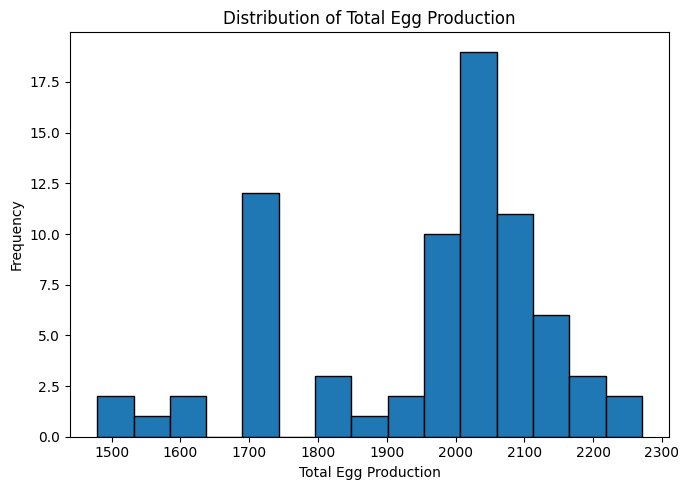

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(
    df["Total_egg_production"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Total Egg Production")
plt.xlabel("Total Egg Production")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:
numeric_columns = [
    "Amount_of_chicken",
    "Amount_of_Feeding",
    "Ammonia",
    "Temperature",
    "Humidity",
    "Light_Intensity",
    "Noise",
    "Total_egg_production"
]

correlations = (
    df[numeric_columns]
    .corr()["Total_egg_production"]
    .sort_values(ascending=False)
)

print(correlations)

Total_egg_production    1.000000
Amount_of_chicken       0.810808
Temperature             0.311872
Humidity                0.120340
Amount_of_Feeding      -0.011042
Light_Intensity        -0.031182
Ammonia                -0.098338
Noise                  -0.122887
Name: Total_egg_production, dtype: float64


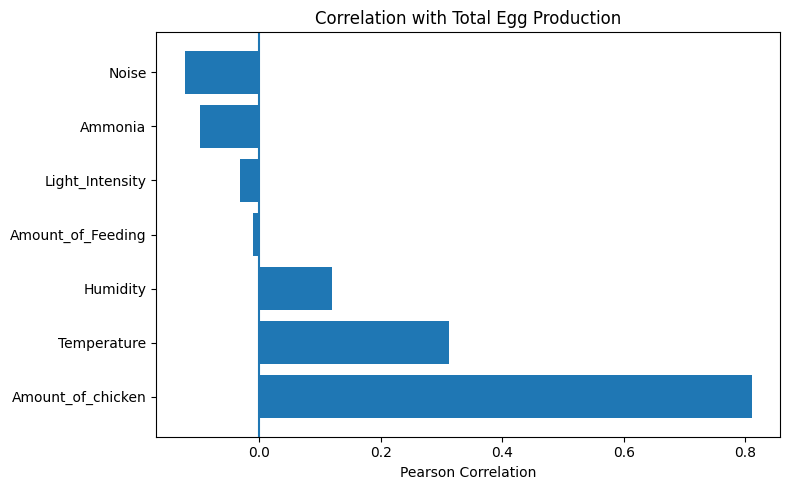

In [ ]:
plt.figure(figsize=(8, 5))

plot_values = correlations.drop(
    "Total_egg_production"
)

plt.barh(
    plot_values.index,
    plot_values.values
)

plt.axvline(0)
plt.title("Correlation with Total Egg Production")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

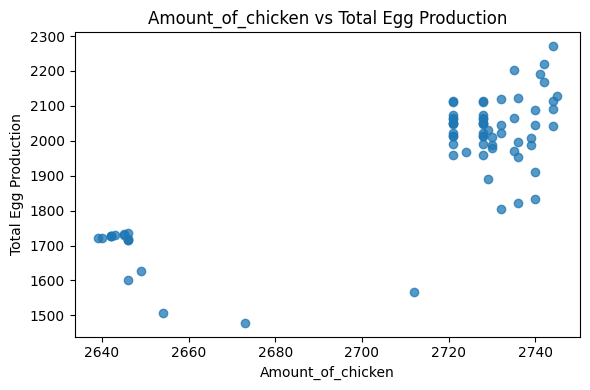

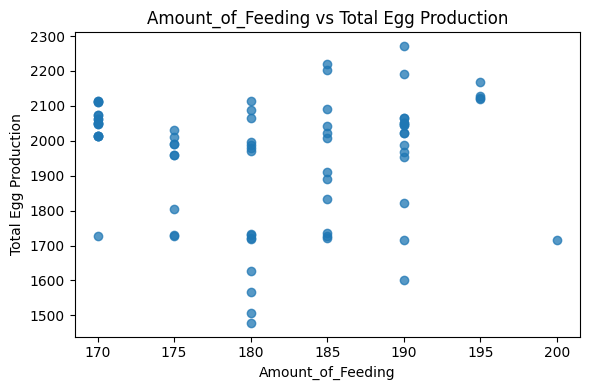

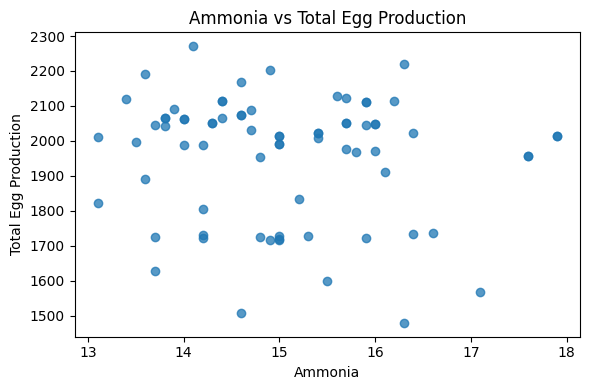

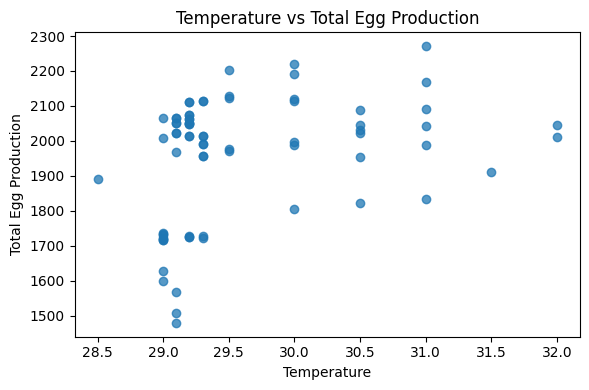

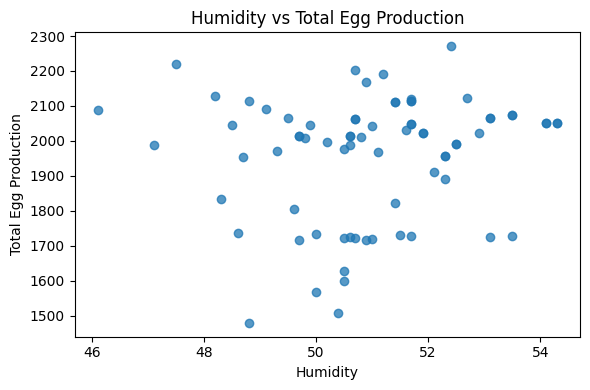

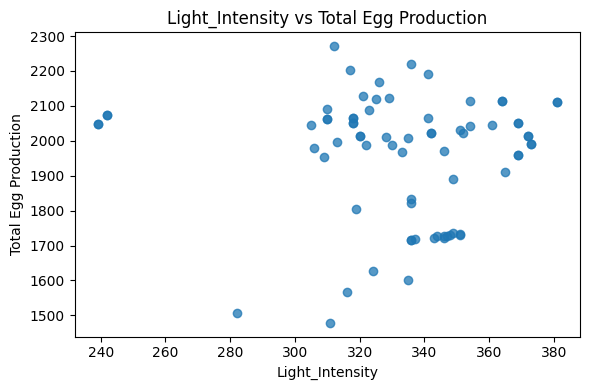

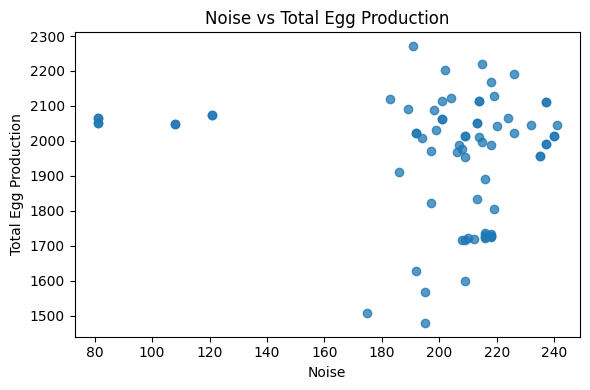

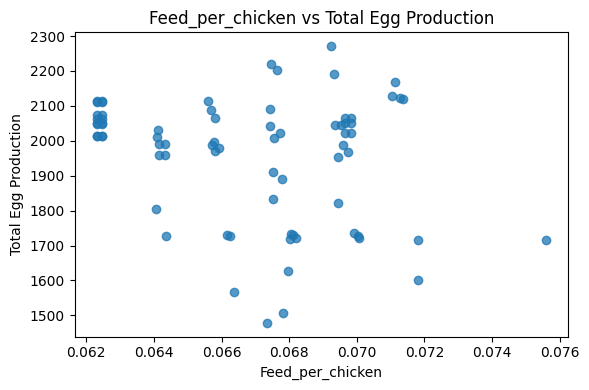

In [ ]:
features_for_plots = [
    "Amount_of_chicken",
    "Amount_of_Feeding",
    "Ammonia",
    "Temperature",
    "Humidity",
    "Light_Intensity",
    "Noise",
    "Feed_per_chicken"
]

for feature in features_for_plots:

    plt.figure(figsize=(6, 4))

    plt.scatter(
        df[feature],
        df["Total_egg_production"],
        alpha=0.75
    )

    plt.title(
        f"{feature} vs Total Egg Production"
    )

    plt.xlabel(feature)
    plt.ylabel("Total Egg Production")
    plt.tight_layout()
    plt.show()

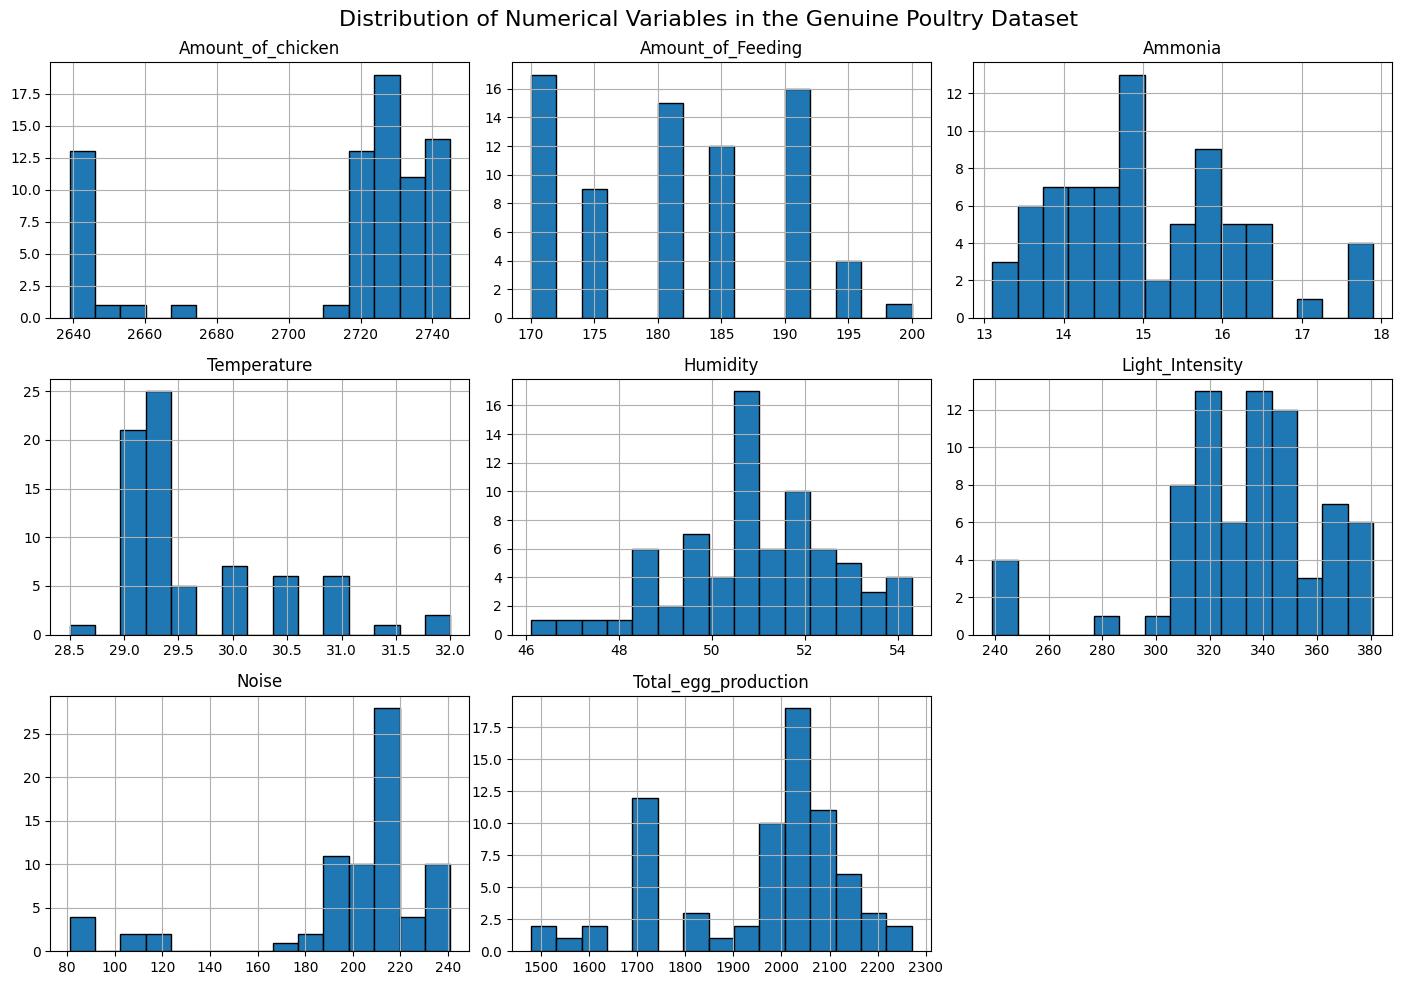

In [ ]:
import matplotlib.pyplot as plt

eda_columns = [
    "Amount_of_chicken",
    "Amount_of_Feeding",
    "Ammonia",
    "Temperature",
    "Humidity",
    "Light_Intensity",
    "Noise",
    "Total_egg_production"
]

df[eda_columns].hist(
    bins=15,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Variables in the Genuine Poultry Dataset",
    fontsize=16
)

plt.tight_layout()
plt.savefig("genuine_poultry_dataset_distribution.png")
plt.show()

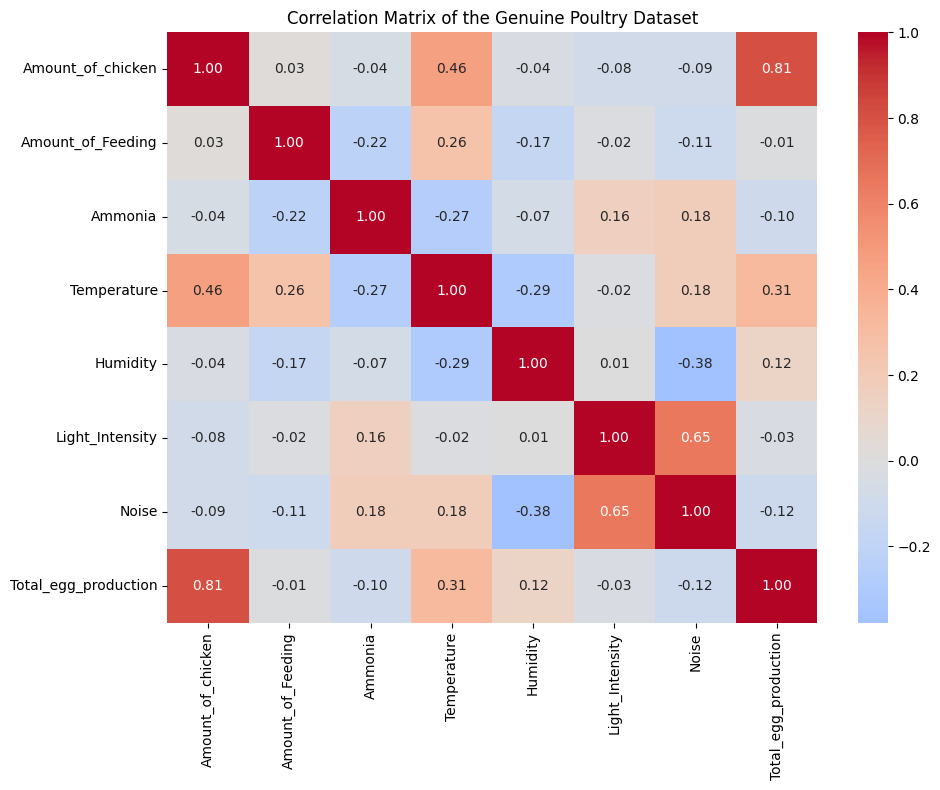

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = df[eda_columns].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of the Genuine Poultry Dataset")
plt.tight_layout()
plt.savefig("genuine_poultry_dataset_correlation.png")
plt.show()

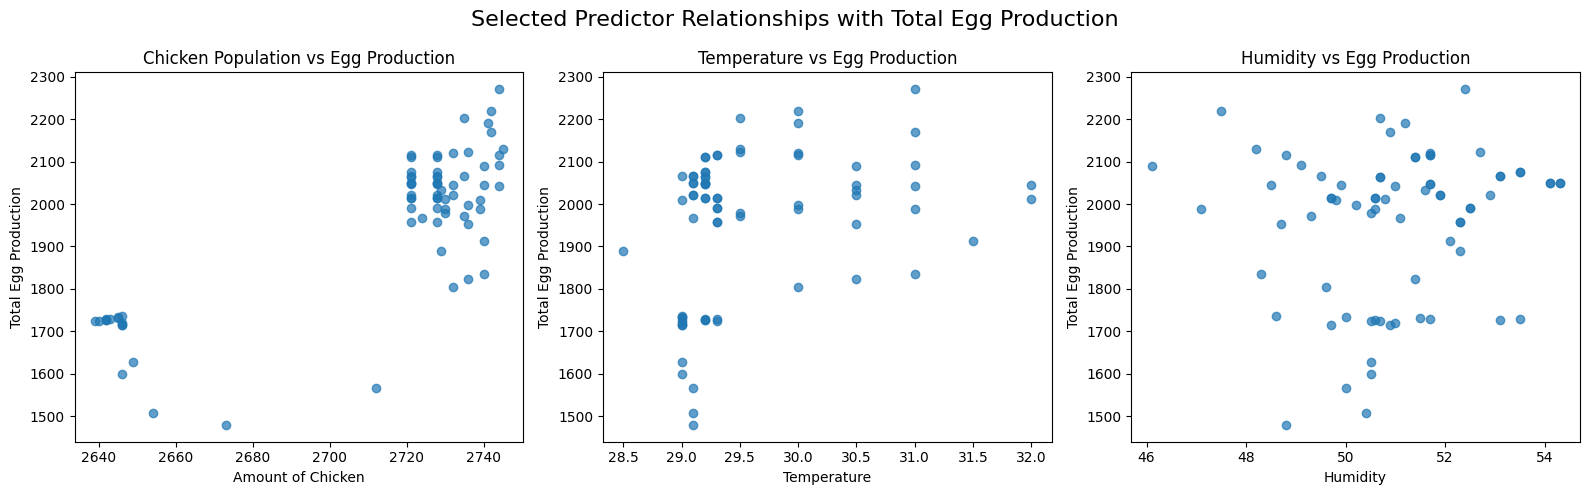

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Chicken population vs egg production
axes[0].scatter(
    df["Amount_of_chicken"],
    df["Total_egg_production"],
    alpha=0.7
)
axes[0].set_xlabel("Amount of Chicken")
axes[0].set_ylabel("Total Egg Production")
axes[0].set_title("Chicken Population vs Egg Production")

# Temperature vs egg production
axes[1].scatter(
    df["Temperature"],
    df["Total_egg_production"],
    alpha=0.7
)
axes[1].set_xlabel("Temperature")
axes[1].set_ylabel("Total Egg Production")
axes[1].set_title("Temperature vs Egg Production")

# Humidity vs egg production
axes[2].scatter(
    df["Humidity"],
    df["Total_egg_production"],
    alpha=0.7
)
axes[2].set_xlabel("Humidity")
axes[2].set_ylabel("Total Egg Production")
axes[2].set_title("Humidity vs Egg Production")

plt.suptitle(
    "Selected Predictor Relationships with Total Egg Production",
    fontsize=16
)

plt.tight_layout()
plt.savefig("selected_predictor_relationships.png")
plt.show()

In [ ]:
FEATURES = [
    "Amount_of_chicken",
    "Amount_of_Feeding",
    "Ammonia",
    "Temperature",
    "Humidity",
    "Light_Intensity",
    "Noise",
    "Feed_per_chicken"
]

TARGET = "Total_egg_production"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (74, 8)
y shape: (74,)


In [ ]:
RANDOM_STATE = 42

X_train_real, X_test_real, y_train_real, y_test_real = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE
    )
)

print("Real training rows:", len(X_train_real))
print("Real testing rows:", len(X_test_real))

Real training rows: 59
Real testing rows: 15


In [ ]:
def fit_gaussian_copula(train_df):

    columns = train_df.columns.tolist()

    latent = pd.DataFrame(
        index=train_df.index
    )

    for column in columns:

        ranks = rankdata(
            train_df[column].values,
            method="average"
        )

        uniform_scores = (
            ranks - 0.5
        ) / len(train_df)

        latent[column] = norm.ppf(
            uniform_scores
        )

    correlation_matrix = (
        latent.corr().values
    )

    eigenvalues, eigenvectors = (
        np.linalg.eigh(
            correlation_matrix
        )
    )

    eigenvalues[
        eigenvalues < 1e-6
    ] = 1e-6

    correlation_matrix = (
        eigenvectors
        @ np.diag(eigenvalues)
        @ eigenvectors.T
    )

    diagonal = np.sqrt(
        np.diag(
            correlation_matrix
        )
    )

    correlation_matrix = (
        correlation_matrix /
        np.outer(
            diagonal,
            diagonal
        )
    )

    return {
        "columns": columns,

        "correlation":
            correlation_matrix,

        "marginals": {
            column:
                np.sort(
                    train_df[column]
                    .astype(float)
                    .values
                )
            for column in columns
        },

        "ranges": {
            column: (
                train_df[column].min(),
                train_df[column].max()
            )
            for column in columns
        }
    }

In [ ]:
def sample_gaussian_copula(
    model,
    number_of_rows,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    columns = model["columns"]

    latent_samples = (
        rng.multivariate_normal(
            mean=np.zeros(
                len(columns)
            ),
            cov=model["correlation"],
            size=number_of_rows
        )
    )

    uniform_samples = norm.cdf(
        latent_samples
    )

    synthetic_df = pd.DataFrame()

    for index, column in enumerate(columns):

        sorted_values = (
            model["marginals"][column]
        )

        empirical_quantiles = (
            np.arange(
                len(sorted_values)
            ) + 0.5
        ) / len(sorted_values)

        generated_values = np.interp(
            uniform_samples[:, index],
            empirical_quantiles,
            sorted_values
        )

        minimum, maximum = (
            model["ranges"][column]
        )

        synthetic_df[column] = np.clip(
            generated_values,
            minimum,
            maximum
        )

    return synthetic_df

In [ ]:
training_joint = X_train_real.copy()

training_joint[TARGET] = (
    y_train_real.values
)

copula_model = fit_gaussian_copula(
    training_joint
)

synthetic_training = (
    sample_gaussian_copula(
        copula_model,
        number_of_rows=250,
        random_state=RANDOM_STATE
    )
)

synthetic_training[
    "Amount_of_chicken"
] = (
    synthetic_training[
        "Amount_of_chicken"
    ]
    .round()
    .astype(int)
)

synthetic_training[
    TARGET
] = (
    synthetic_training[
        TARGET
    ]
    .round()
    .astype(int)
)

synthetic_training[
    TARGET
] = np.minimum(
    synthetic_training[TARGET],
    synthetic_training[
        "Amount_of_chicken"
    ]
)

synthetic_training[
    "Feed_per_chicken"
] = (
    synthetic_training[
        "Amount_of_Feeding"
    ] /
    synthetic_training[
        "Amount_of_chicken"
    ]
)

synthetic_training.head()

,Amount_of_chicken,Amount_of_Feeding,Ammonia,Temperature,Humidity,Light_Intensity,Noise,Feed_per_chicken,Total_egg_production
0,2646,180.0,13.950328,29.300000,50.500000,297.843706,191.457735,0.068027,1535
1,2741,180.0,15.359451,29.799155,51.050858,323.340573,188.018553,0.065669,2173
2,2721,180.0,16.300000,29.100000,52.319354,351.000000,213.514008,0.066152,1967
3,2728,175.0,15.900000,29.500000,48.131698,312.987393,191.944204,0.064150,1728
4,2729,190.0,15.700000,29.200000,49.490551,346.000000,209.009891,0.069623,1958


In [ ]:
X_train_synthetic = (
    synthetic_training[FEATURES]
)

y_train_synthetic = (
    synthetic_training[TARGET]
)

X_train_augmented = pd.concat(
    [
        X_train_real,
        X_train_synthetic
    ],
    ignore_index=True
)

y_train_augmented = pd.concat(
    [
        y_train_real.reset_index(
            drop=True
        ),
        y_train_synthetic.reset_index(
            drop=True
        )
    ],
    ignore_index=True
)

print(
    "Augmented training rows:",
    len(X_train_augmented)
)

Augmented training rows: 309


In [ ]:
def evaluate_model(
    model_name,
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [ ]:
linear_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

linear_model.fit(
    X_train_augmented,
    y_train_augmented
)

linear_predictions = (
    linear_model.predict(
        X_test_real
    )
)

linear_results = evaluate_model(
    "Linear Regression",
    y_test_real,
    linear_predictions
)

linear_results

{'Model': 'Linear Regression',
 'MAE': 79.61206047844452,
 'RMSE': np.float64(96.81626529922433),
 'R2': 0.3949032809416032}

In [ ]:
random_forest_model = (
    RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

random_forest_model.fit(
    X_train_augmented,
    y_train_augmented
)

random_forest_predictions = (
    random_forest_model.predict(
        X_test_real
    )
)

random_forest_results = (
    evaluate_model(
        "Random Forest",
        y_test_real,
        random_forest_predictions
    )
)

random_forest_results

{'Model': 'Random Forest',
 'MAE': 62.3036666666667,
 'RMSE': np.float64(84.74999735496556),
 'R2': 0.5363315630151824}

In [ ]:
xgboost_model = XGBRegressor(
    n_estimators=180,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgboost_model.fit(
    X_train_augmented,
    y_train_augmented
)

xgboost_predictions = (
    xgboost_model.predict(
        X_test_real
    )
)

xgboost_results = evaluate_model(
    "XGBoost",
    y_test_real,
    xgboost_predictions
)

xgboost_results

{'Model': 'XGBoost',
 'MAE': 77.55646514892578,
 'RMSE': np.float64(97.55285025948756),
 'R2': 0.3856610655784607}

In [ ]:
model_results = pd.DataFrame([
    linear_results,
    random_forest_results,
    xgboost_results
])

model_results = (
    model_results
    .sort_values("RMSE")
    .reset_index(drop=True)
)

model_results

,Model,MAE,RMSE,R2
0,Random Forest,62.303667,84.749997,0.536332
1,Linear Regression,79.612060,96.816265,0.394903
2,XGBoost,77.556465,97.552850,0.385661


In [ ]:
random_forest_parameters = {
    "n_estimators": [
        150,
        300
    ],

    "max_depth": [
        None,
        6
    ],

    "min_samples_leaf": [
        1,
        2
    ]
}

random_forest_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    param_grid=random_forest_parameters,

    scoring=(
        "neg_root_mean_squared_error"
    ),

    cv=3,

    n_jobs=-1
)

random_forest_search.fit(
    X_train_augmented,
    y_train_augmented
)

print(
    random_forest_search.best_params_
)

{'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 300}


In [ ]:
best_random_forest = (
    random_forest_search
    .best_estimator_
)

tuned_rf_predictions = (
    best_random_forest.predict(
        X_test_real
    )
)

tuned_rf_results = evaluate_model(
    "Tuned Random Forest",
    y_test_real,
    tuned_rf_predictions
)

tuned_rf_results

{'Model': 'Tuned Random Forest',
 'MAE': 63.87961984764106,
 'RMSE': np.float64(84.6546569676106),
 'R2': 0.5373741934477911}

In [ ]:
xgboost_parameters = {
    "n_estimators": [
        150,
        250
    ],

    "learning_rate": [
        0.05,
        0.10
    ],

    "max_depth": [
        2,
        3
    ]
}

xgboost_search = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    param_grid=xgboost_parameters,

    scoring=(
        "neg_root_mean_squared_error"
    ),

    cv=3,

    n_jobs=-1
)

xgboost_search.fit(
    X_train_augmented,
    y_train_augmented
)

print(
    xgboost_search.best_params_
)

{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 150}


In [ ]:
best_xgboost = (
    xgboost_search.best_estimator_
)

tuned_xgb_predictions = (
    best_xgboost.predict(
        X_test_real
    )
)

tuned_xgb_results = evaluate_model(
    "Tuned XGBoost",
    y_test_real,
    tuned_xgb_predictions
)

tuned_xgb_results

{'Model': 'Tuned XGBoost',
 'MAE': 72.8362045288086,
 'RMSE': np.float64(94.60068730755872),
 'R2': 0.4222809672355652}

In [ ]:
final_results = pd.DataFrame([
    linear_results,
    random_forest_results,
    xgboost_results,
    tuned_rf_results,
    tuned_xgb_results
])

final_results = (
    final_results
    .sort_values("RMSE")
    .reset_index(drop=True)
)

final_results

,Model,MAE,RMSE,R2
0,Tuned Random Forest,63.879620,84.654657,0.537374
1,Random Forest,62.303667,84.749997,0.536332
2,Tuned XGBoost,72.836205,94.600687,0.422281
3,Linear Regression,79.612060,96.816265,0.394903
4,XGBoost,77.556465,97.552850,0.385661


In [ ]:
cross_validation = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_models = {
    "Linear Regression":
        linear_model,

    "Random Forest":
        random_forest_model,

    "XGBoost":
        xgboost_model
}

cv_results = []

for model_name, model in cv_models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cross_validation,

        scoring={
            "MAE":
                "neg_mean_absolute_error",

            "RMSE":
                "neg_root_mean_squared_error",

            "R2":
                "r2"
        },

        n_jobs=-1
    )

    cv_results.append({
        "Model":
            model_name,

        "CV_MAE":
            -scores["test_MAE"].mean(),

        "CV_RMSE":
            -scores["test_RMSE"].mean(),

        "CV_R2":
            scores["test_R2"].mean()
    })

cv_results_df = pd.DataFrame(
    cv_results
)

cv_results_df = (
    cv_results_df
    .sort_values("CV_RMSE")
    .reset_index(drop=True)
)

cv_results_df

,Model,CV_MAE,CV_RMSE,CV_R2
0,XGBoost,63.116458,90.071004,0.714300
1,Random Forest,60.352519,91.477747,0.705299
2,Linear Regression,84.858192,108.686518,0.586288


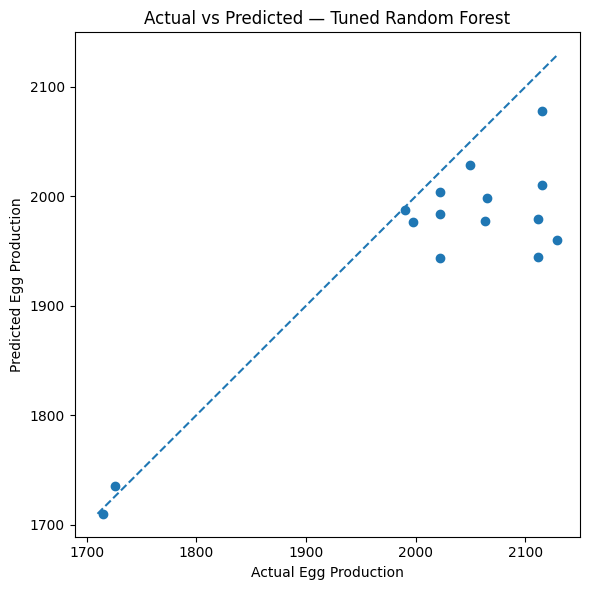

In [ ]:
best_model_name = (
    final_results.iloc[0]["Model"]
)

if best_model_name == "Tuned Random Forest":

    best_predictions = (
        tuned_rf_predictions
    )

elif best_model_name == "Random Forest":

    best_predictions = (
        random_forest_predictions
    )

elif best_model_name == "Tuned XGBoost":

    best_predictions = (
        tuned_xgb_predictions
    )

elif best_model_name == "XGBoost":

    best_predictions = (
        xgboost_predictions
    )

else:

    best_predictions = (
        linear_predictions
    )

plt.figure(figsize=(6, 6))

plt.scatter(
    y_test_real,
    best_predictions
)

minimum_value = min(
    y_test_real.min(),
    best_predictions.min()
)

maximum_value = max(
    y_test_real.max(),
    best_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted — {best_model_name}"
)

plt.xlabel("Actual Egg Production")
plt.ylabel("Predicted Egg Production")
plt.tight_layout()
plt.show()

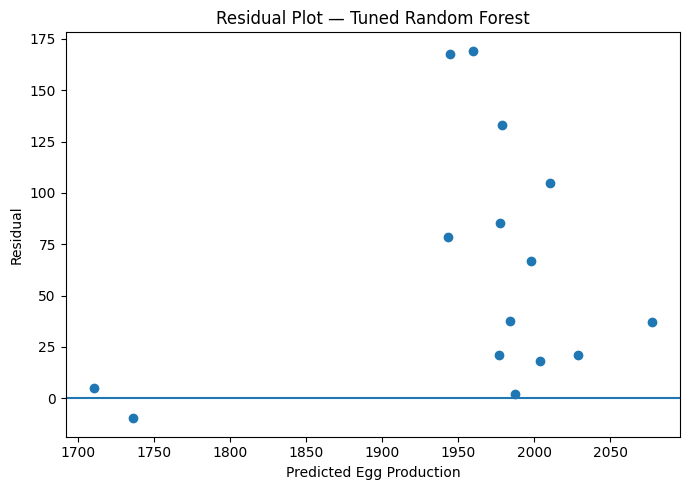

In [ ]:
residuals = (
    y_test_real.values -
    best_predictions
)

plt.figure(figsize=(7, 5))

plt.scatter(
    best_predictions,
    residuals
)

plt.axhline(0)

plt.title(
    f"Residual Plot — {best_model_name}"
)

plt.xlabel("Predicted Egg Production")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

In [ ]:
shap_model = best_xgboost

shap_explainer = shap.TreeExplainer(
    shap_model
)

shap_values = (
    shap_explainer.shap_values(
        X_test_real
    )
)

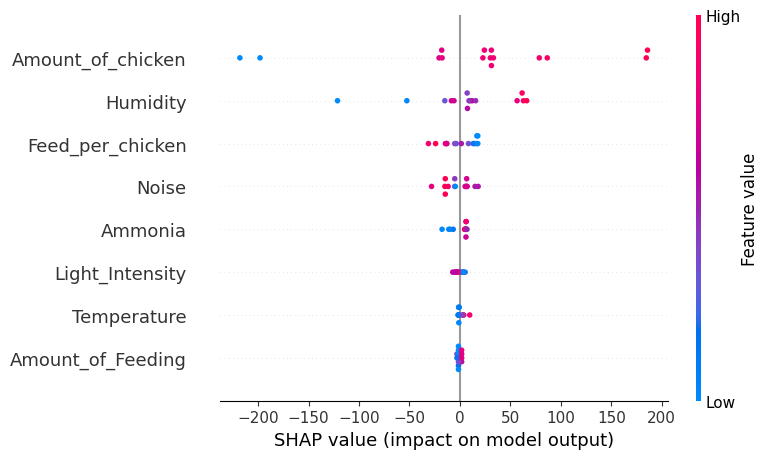

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_real
)

In [ ]:
mean_absolute_shap = (
    np.abs(
        shap_values
    ).mean(axis=0)
)

shap_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Absolute_SHAP":
        mean_absolute_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
)

shap_importance

,Feature,Mean_Absolute_SHAP
0,Amount_of_chicken,78.742256
4,Humidity,34.126911
7,Feed_per_chicken,14.082281
6,Noise,10.895298
2,Ammonia,7.302553
5,Light_Intensity,3.215580
3,Temperature,2.144179
1,Amount_of_Feeding,1.715263


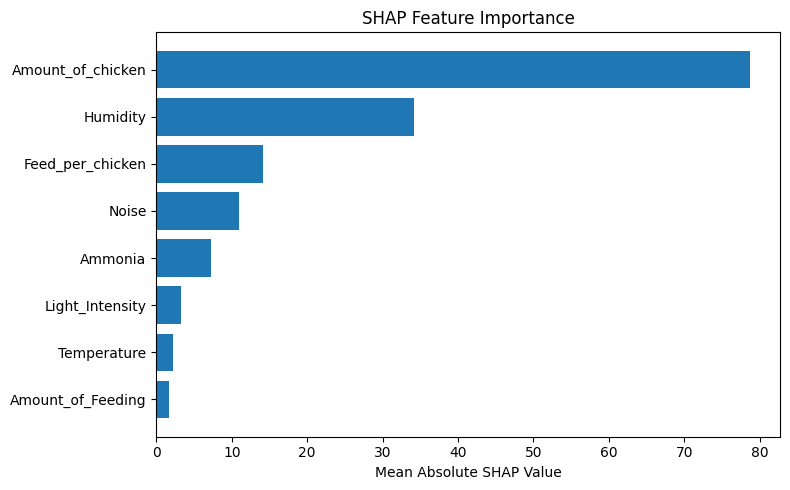

In [ ]:
plt.figure(figsize=(8, 5))

plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance[
        "Mean_Absolute_SHAP"
    ][::-1]
)

plt.title("SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()
plt.savefig("shap_feature_importance.png")
plt.show()

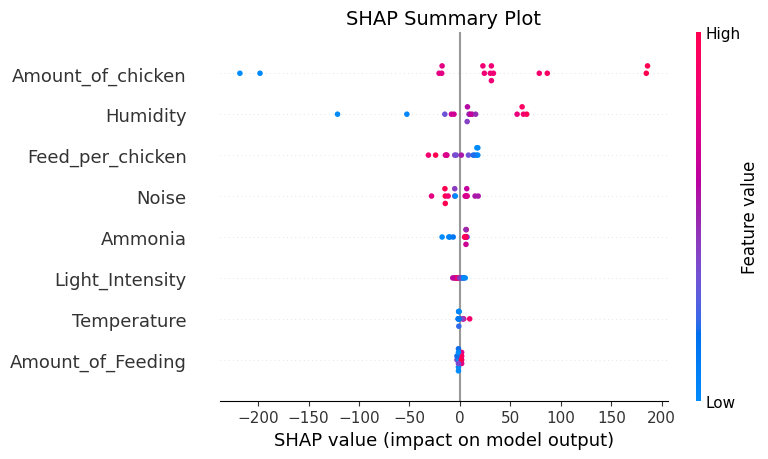

In [ ]:
import shap
import matplotlib.pyplot as plt

# SHAP Summary Plot
plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    X_test_real,
    feature_names=X_test_real.columns,
    show=False
)

plt.title("SHAP Summary Plot", fontsize=14)
plt.tight_layout()

# Save for Power BI
plt.savefig(
    "shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "shap_summary_plot.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
prediction_export = (
    X_test_real
    .reset_index(drop=True)
    .copy()
)

prediction_export[
    "Actual_egg_production"
] = (
    y_test_real
    .reset_index(drop=True)
)

prediction_export[
    "Linear_Regression_Prediction"
] = linear_predictions

prediction_export[
    "Random_Forest_Prediction"
] = random_forest_predictions

prediction_export[
    "XGBoost_Prediction"
] = xgboost_predictions

prediction_export[
    "Tuned_Random_Forest_Prediction"
] = tuned_rf_predictions

prediction_export[
    "Tuned_XGBoost_Prediction"
] = tuned_xgb_predictions

prediction_export.head()

,Amount_of_chicken,Amount_of_Feeding,Ammonia,Temperature,Humidity,Light_Intensity,Noise,Feed_per_chicken,Actual_egg_production,Linear_Regression_Prediction,Random_Forest_Prediction,XGBoost_Prediction,Tuned_Random_Forest_Prediction,Tuned_XGBoost_Prediction
0,2728,170,15.9,29.2,51.4,381,237,0.062317,2112,1975.952092,1972.305,1967.285767,1978.995217,1973.928589
1,2721,175,15.0,29.3,52.5,373,237,0.064315,1990,1990.682775,1990.625,1975.834595,1987.676429,1971.029419
2,2646,200,14.9,29.0,50.9,336,208,0.075586,1715,1585.574248,1721.970,1748.669800,1709.968089,1734.371704
3,2728,170,14.4,29.3,51.7,364,214,0.062317,2115,1975.194760,2055.060,2030.248047,2010.131766,2007.205933
4,2642,175,13.7,29.2,50.6,344,216,0.066238,1726,1676.399961,1747.720,1682.272217,1735.723542,1701.606445


In [ ]:
OUTPUT_FOLDER = "/content/powerbi_exports"

os.makedirs(
    OUTPUT_FOLDER,
    exist_ok=True
)

prediction_export.to_csv(
    f"{OUTPUT_FOLDER}/predictions_real_test.csv",
    index=False
)

final_results.to_csv(
    f"{OUTPUT_FOLDER}/model_comparison_holdout.csv",
    index=False
)

cv_results_df.to_csv(
    f"{OUTPUT_FOLDER}/cross_validation_results.csv",
    index=False
)

shap_importance.to_csv(
    f"{OUTPUT_FOLDER}/shap_feature_importance.csv",
    index=False
)

df.to_csv(
    f"{OUTPUT_FOLDER}/clean_real_dataset.csv",
    index=False
)

synthetic_training.to_csv(
    f"{OUTPUT_FOLDER}/synthetic_training_only.csv",
    index=False
)

print("Files exported successfully.")

Files exported successfully.


In [ ]:
from google.colab import files

files.download(
    f"{OUTPUT_FOLDER}/predictions_real_test.csv"
)

files.download(
    f"{OUTPUT_FOLDER}/model_comparison_holdout.csv"
)

files.download(
    f"{OUTPUT_FOLDER}/cross_validation_results.csv"
)

files.download(
    f"{OUTPUT_FOLDER}/shap_feature_importance.csv"
)

files.download(
    f"{OUTPUT_FOLDER}/clean_real_dataset.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>